# Vision — Klasifikasi Klasik (HOG + histogram warna + model sklearn)
**Kapan dipakai:** tanpa GPU / waktu sangat sedikit, gambar kecil dan sederhana, atau sebagai
pembanding cepat sebelum memakai embedding pretrained (`vision/klasifikasi_embedding`).

**Langkah:** tiap gambar → fitur HOG (bentuk/tepi) + histogram warna → model sklearn biasa.

**Data demo:** CIFAR-10 kecil (gambar 32x32, 10 kelas).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from PIL import Image
from skimage.feature import hog
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
COLOR_BINS = 16       # jumlah kotak histogram per warna
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())
train.head()

train: (4000, 2) | test: (1000, 2)
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


,path,label
0,train/airplane/0000.png,airplane
1,train/airplane/0001.png,airplane
2,train/airplane/0002.png,airplane
3,train/airplane/0003.png,airplane
4,train/airplane/0004.png,airplane


## Lihat contoh gambar

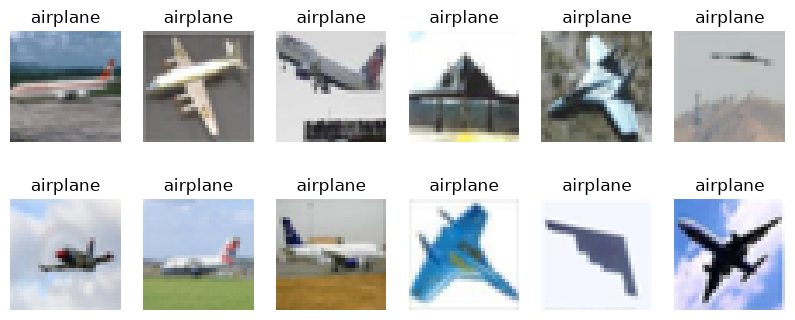

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, path, label in zip(axes.flat, train[PATH_COL][:12], train[TARGET][:12]):
    ax.imshow(Image.open(f"{DATA_FOLDER}/{path}"))
    ax.set_title(label)
    ax.axis("off")
plt.show()

## Fitur: HOG + histogram warna
HOG = arah tepi di tiap kotak 8×8 piksel (bentuk). Histogram = sebaran nilai tiap warna R/G/B.

In [5]:
def image_features(path):
    image = np.asarray(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB"))
    shape_part = hog(image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                     channel_axis=-1)
    parts = [shape_part]
    for channel in range(3):
        counts, edges = np.histogram(image[:, :, channel], bins=COLOR_BINS, range=(0, 256))
        parts.append(counts)
    return np.concatenate(parts)


print("panjang fitur satu gambar:", len(image_features(train.loc[0, PATH_COL])))

train_features = []
for path in train[PATH_COL]:
    train_features.append(image_features(path))
test_features = []
for path in test[PATH_COL]:
    test_features.append(image_features(path))
X_all = np.array(train_features)
X_test = np.array(test_features)
print("train:", X_all.shape, "| test:", X_test.shape)

panjang fitur satu gambar: 372


train: (4000, 372) | test: (1000, 372)


## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_all, train[TARGET], test_size=0.2, stratify=train[TARGET], random_state=SEED
)

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai.

In [7]:
model = make_pipeline(StandardScaler(), LinearSVC(C=0.1))
# model = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000))
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
# model = RandomForestClassifier(n_estimators=300, random_state=SEED)
# model = ExtraTreesClassifier(n_estimators=300, random_state=SEED)
# model = LGBMClassifier(n_estimators=300, verbose=-1, random_state=SEED)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearsvc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['airplane','automobile','bird',...,'horse','ship','truck']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,372
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluasi di validasi

F1 macro: 0.4531
              precision    recall  f1-score   support

    airplane       0.49      0.54      0.51        80
  automobile       0.58      0.53      0.55        80
        bird       0.42      0.31      0.36        80
         cat       0.30      0.28      0.29        80
        deer       0.30      0.33      0.31        80
         dog       0.37      0.31      0.34        80
        frog       0.51      0.66      0.58        80
       horse       0.52      0.51      0.52        80
        ship       0.53      0.54      0.53        80
       truck       0.52      0.57      0.54        80

    accuracy                           0.46       800
   macro avg       0.45      0.46      0.45       800
weighted avg       0.45      0.46      0.45       800



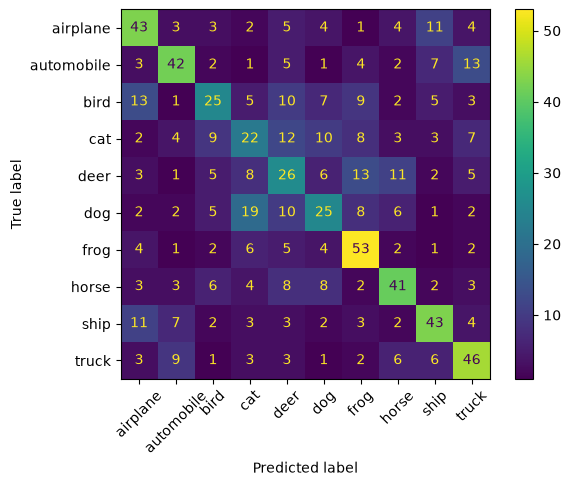

In [8]:
val_predictions = model.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=45)
plt.show()

## Latih ulang di semua data + submission

In [9]:
model.fit(X_all, train[TARGET])
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,airplane
1,2,airplane
2,3,airplane
3,4,ship
4,5,airplane


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["label"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 0.4776
